In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("./data/shapes.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

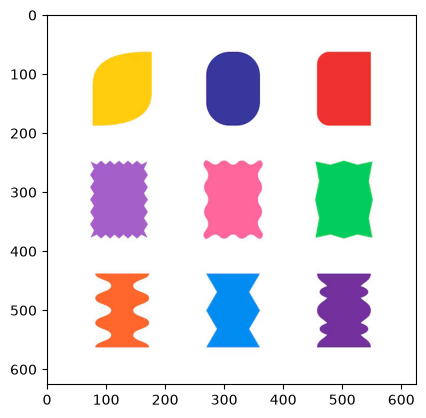

In [3]:
plt.imshow(img_rgb)

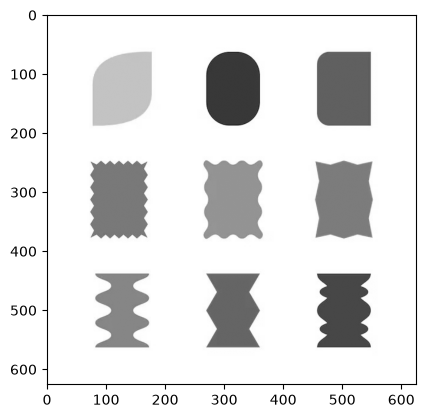

In [4]:
plt.imshow(img_gray, 'gray')

### Helper function

In [56]:
def view_images(mask, final_img, text, original_img=img_rgb):
    final_img_rgb = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB)
    images = {"Original image": original_img, 
              "Masking": mask, 
              "Contoured image": final_img_rgb}
    fig, axs = plt.subplots(1,3, figsize=(12,5))
    for i, (title, image) in enumerate(images.items()):
        axs[i].imshow(image, cmap="gray" if image.ndim == 2 else None)
        axs[i].set_title(title)
        axs[i].axis('off')

    plt.suptitle(text, size=12, weight='bold')
    plt.tight_layout()
    plt.show()

### Apply `Canny` edge detection

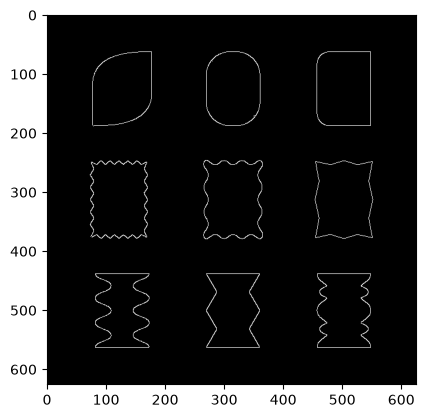

In [43]:
canny_mask = cv2.Canny(image=img_gray, threshold1=50, threshold2=150)
plt.imshow(canny_mask, 'grey')

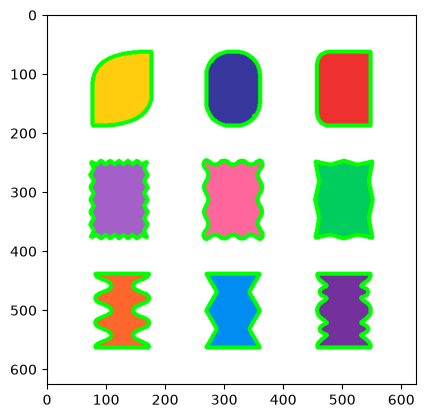

In [44]:
# Function to detect contours (boundaries of objects) in a binary image.
contours, herarchy = cv2.findContours(image=canny_mask, 
                                      mode=cv2.RETR_LIST, # retrieves all contours without organizing them into a parent-child hierarchy.
                                      method=cv2.CHAIN_APPROX_SIMPLE) # compress contours by storing only essential points
'''
mode    : hirarchy relationship between contours
method  : contours points are stored 
'''

contour_img = img.copy()
cv2.drawContours(image=contour_img, 
                 contours=contours, 
                 contourIdx=-1, # draw all contours
                 color=(0,255,0), 
                 thickness=6)

contour_img_rgb = cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB)
plt.imshow(contour_img_rgb)

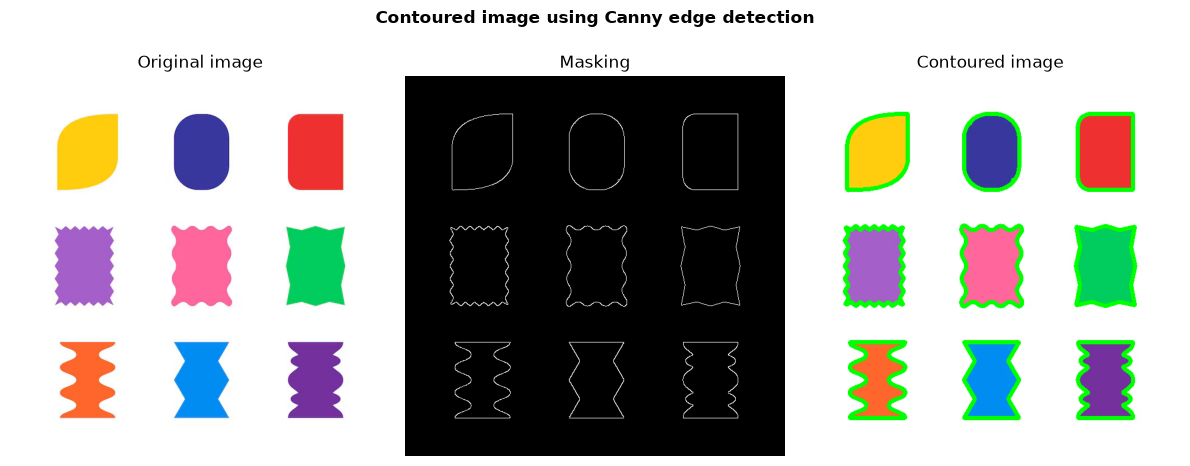

In [45]:
view_images(canny_mask, contour_img, "Contoured image using Canny edge detection")

### Applying `Thresholding` method

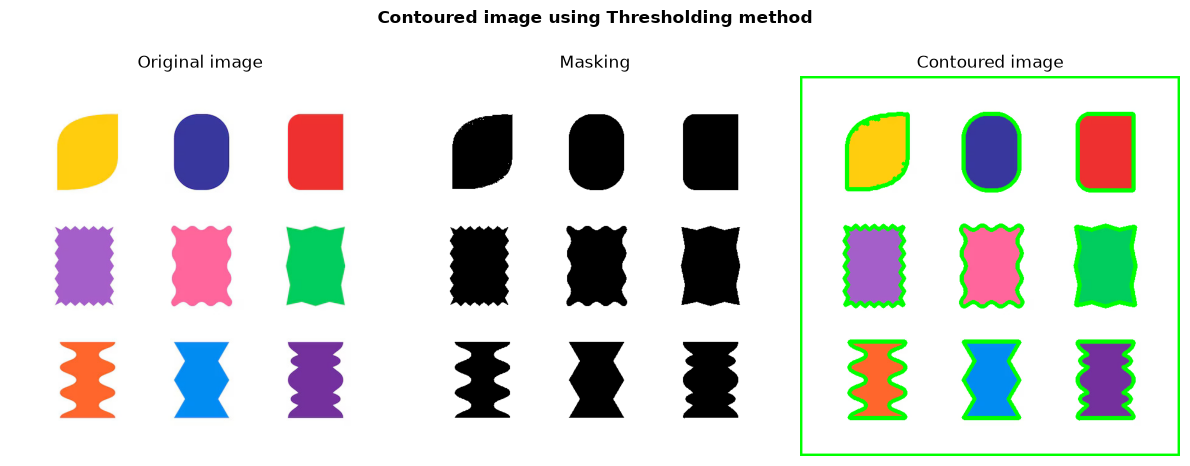

In [46]:
retval, binary_mask = cv2.threshold(src=img_gray, 
                                    thresh=200, 
                                    maxval=255, 
                                    type=cv2.THRESH_BINARY)

# Function to detect contours (boundaries of objects) in a binary image.
contours, herarchy = cv2.findContours(image=binary_mask, 
                                      mode=cv2.RETR_LIST, # retrieves all contours without organizing them into a parent-child hierarchy.
                                      method=cv2.CHAIN_APPROX_SIMPLE) # compress contours by storing only essential points

contour_img = img.copy()
cv2.drawContours(image=contour_img, 
                 contours=contours, 
                 contourIdx=-1, # draw all contours
                 color=(0,255,0), 
                 thickness=6)

view_images(binary_mask, contour_img, "Contoured image using Thresholding method")

### Applying `Thresholding` method using HSV image

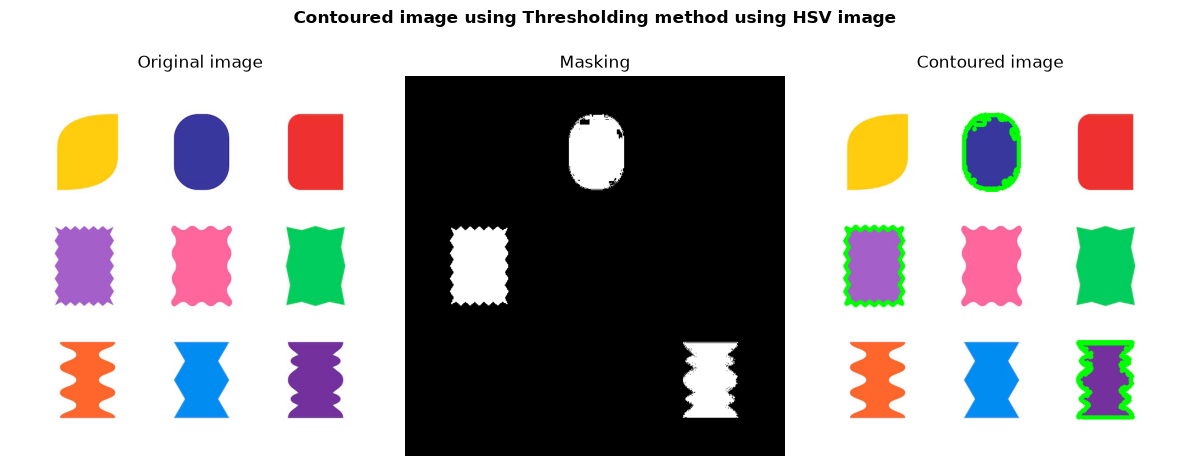

In [57]:
lower = np.array([120, 80, 0], dtype=np.uint8)
upper = np.array([160, 185, 255], dtype=np.uint8)

img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

bounding_mask = cv2.inRange(src=img_hsv, lowerb=lower, upperb=upper)

# Function to detect contours (boundaries of objects) in a binary image.
contours, herarchy = cv2.findContours(image=bounding_mask, 
                                      mode=cv2.RETR_LIST, # retrieves all contours without organizing them into a parent-child hierarchy.
                                      method=cv2.CHAIN_APPROX_SIMPLE) # compress contours by storing only essential points

contour_img = img.copy()
cv2.drawContours(image=contour_img, 
                 contours=contours, 
                 contourIdx=-1, # draw all contours
                 color=(0,255,0), 
                 thickness=6)

view_images(bounding_mask, contour_img, "Contoured image using Thresholding method using HSV image")

### Applying `Thresholding` method using gray-scaled image

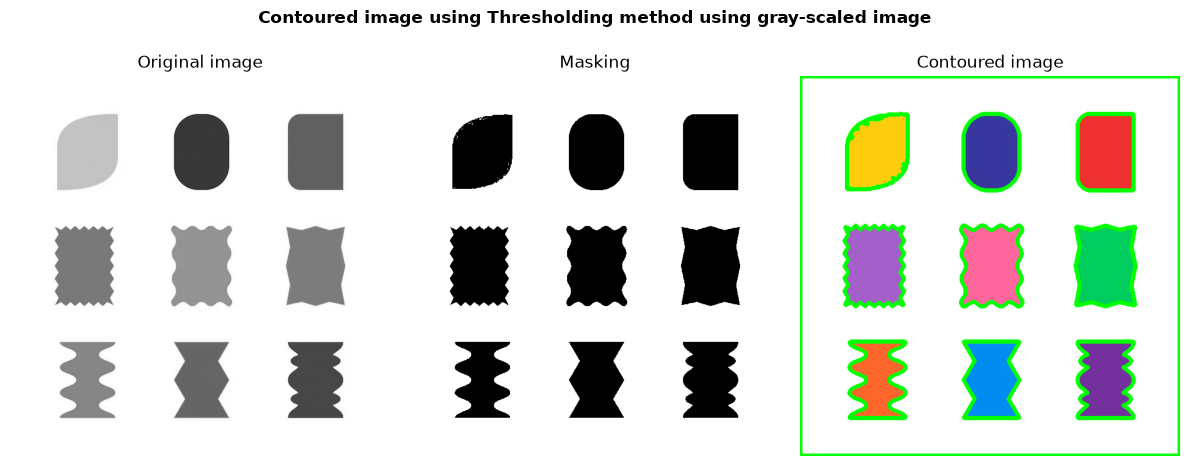

In [ ]:
lower = np.array([200], dtype=np.uint8)
upper = np.array([255], dtype=np.uint8)

bounding_mask = cv2.inRange(src=img_gray, lowerb=lower, upperb=upper)

# Function to detect contours (boundaries of objects) in a binary image.
contours, herarchy = cv2.findContours(image=bounding_mask, 
                                      mode=cv2.RETR_LIST, # retrieves all contours without organizing them into a parent-child hierarchy.
                                      method=cv2.CHAIN_APPROX_SIMPLE) # compress contours by storing only essential points

contour_img = img.copy()
cv2.drawContours(image=contour_img, 
                 contours=contours, 
                 contourIdx=-1, # draw all contours
                 color=(0,255,0), 
                 thickness=6)


view_images(bounding_mask, contour_img, "Contoured image using Thresholding method using gray-scaled image", img_gray)

In [60]:
lower = np.array([200], dtype=np.uint8)
upper = np.array([255], dtype=np.uint8)

bounding_mask = cv2.inRange(src=img_gray, lowerb=lower, upperb=upper)

# Function to detect contours (boundaries of objects) in a binary image.
contours, herarchy = cv2.findContours(image=bounding_mask, 
                                      mode=cv2.RETR_LIST, # retrieves all contours without organizing them into a parent-child hierarchy.
                                      method=cv2.CHAIN_APPROX_SIMPLE) # compress contours by storing only essential points

contour_img = img.copy()
cv2.drawContours(image=contour_img, 
                 contours=contours, 
                 contourIdx=-1, # draw all contours
                 color=(0,255,0), 
                 thickness=6)

sorted_contours = sorted(contours, key=cv2.contourArea, reverse=True)

print(len(sorted_contours))

contours = sorted_contours[1:5]

# view_images(bounding_mask, contour_img, "Contoured image using Thresholding method using gray-scaled image", img_gray)

32


32


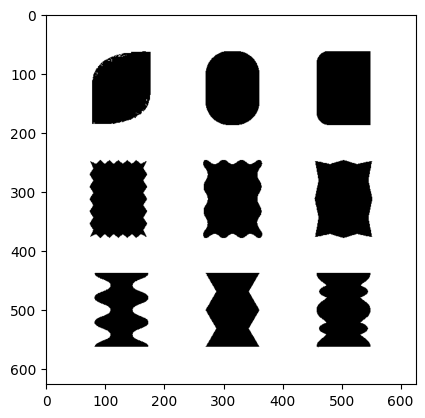

In [20]:
import numpy as np

lower_bound = np.array([200], dtype=np.uint8)
upper_bound = np.array([255], dtype=np.uint8)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
image_grey = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

mask = cv2.inRange(image_grey, lower_bound, upper_bound)

plt.imshow(mask, cmap='grey')

contours, hierarchy = cv2.findContours(mask, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

sorted_contours = sorted(contours, key=cv2.contourArea,reverse=True)

print(len(sorted_contours))

contours = sorted_contours[1:10]

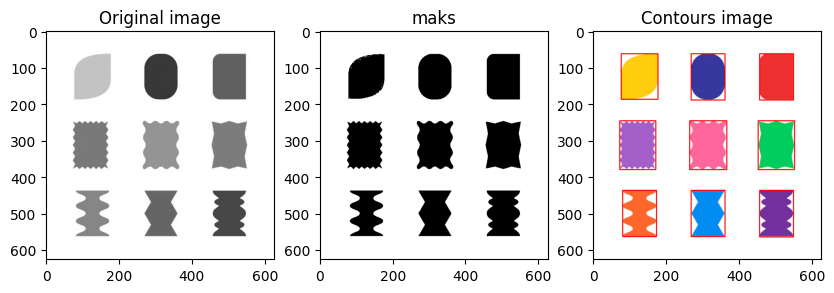

In [22]:
#MODE - hierarchy relationship between contours
# method - contours points are stored.
contour_image = image.copy()

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(contour_image, (x,y), (x+w, y+h), (0,0,255), 2)


# cv2.drawContours(contour_image, contours, -1, (0, 255, 0), 5)

plt.figure(figsize=(10,5))
plt.subplot(1,3,1)
plt.imshow(image_grey, cmap='grey')
plt.title("Original image")

plt.subplot(1,3,2)
plt.imshow(mask, cmap='grey')
plt.title("maks")

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
plt.title("Contours image")

plt.show()